Local file 'Retail_Sales_Data.csv' not found. Creating a sample retail dataset for demonstration...

Initial DataFrame Head:
  Region Product_Category  Sales_Amount
0   East            Books   1629.322299
1   West      Electronics   1799.975752
2  North         Clothing    687.156689
3   East   Home & Kitchen    286.849955
4   East      Electronics    513.775188

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Region            120 non-null    object 
 1   Product_Category  120 non-null    object 
 2   Sales_Amount      120 non-null    float64
dtypes: float64(1), object(2)
memory usage: 2.9+ KB
None

Missing values:
 Region              0
Product_Category    0
Sales_Amount        0
dtype: int64

Regional Sales:
 Region
West     38665.762316
South    32131.408324
East     26646.449062
North    23237.044550
Name: Sales_

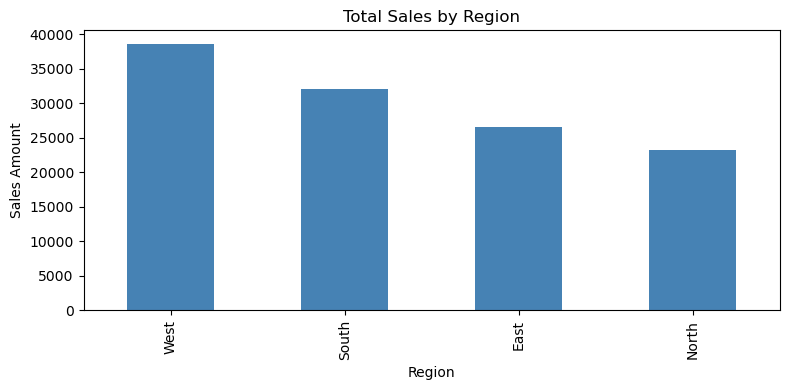

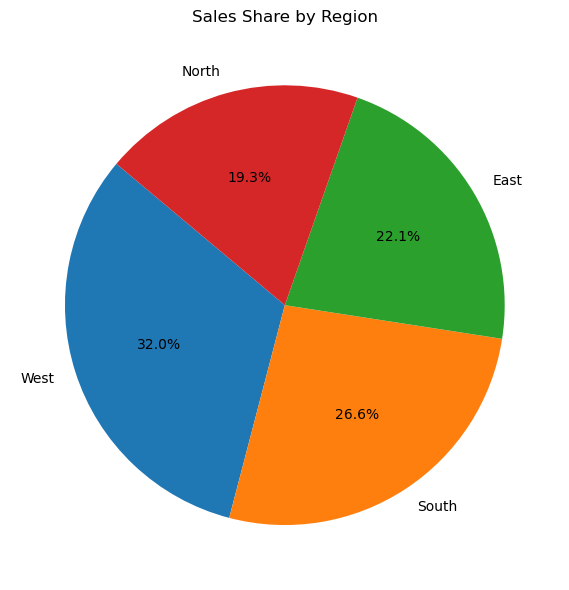


Pivot Table (Region vs Product Category):
 Product_Category         Books     Clothing   Electronics  Home & Kitchen
Region                                                                   
East               9505.101916     0.000000  11631.435127     5509.912020
North              1768.178963  6889.431284   5329.509969     9249.924334
South              8633.014698  4007.589791   9411.298337    10079.505498
West              10568.977798  6301.549029   9829.648492    11965.586998


<Figure size 900x500 with 0 Axes>

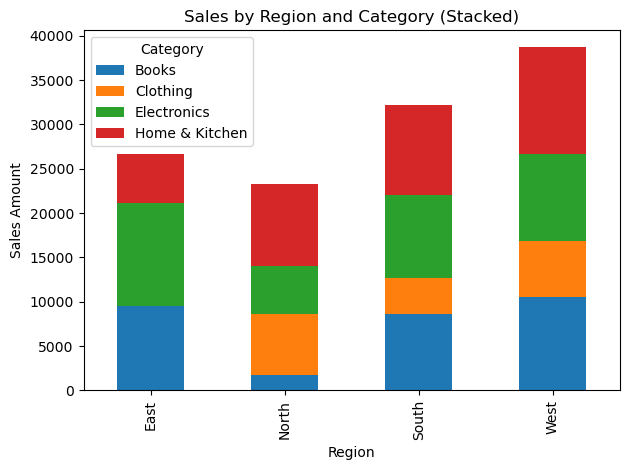

<Figure size 900x500 with 0 Axes>

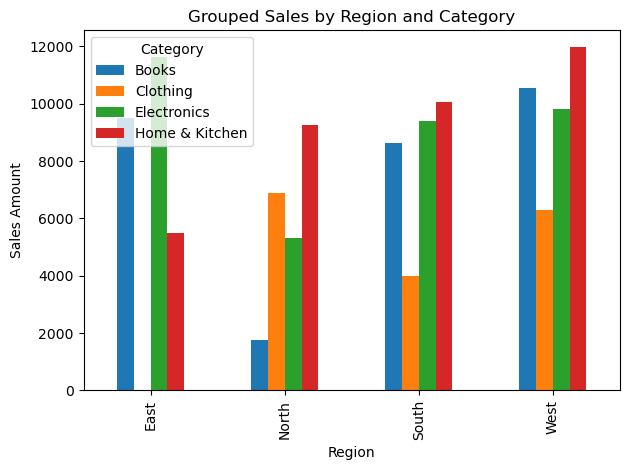

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    df = pd.read_csv("Retail_Sales_Data.csv")
    print("Successfully loaded 'Retail_Sales_Data.csv' from local storage.")
except FileNotFoundError:
    print("Local file 'Retail_Sales_Data.csv' not found. Creating a sample retail dataset for demonstration...")
    np.random.seed(42)
    regions = ["North", "South", "East", "West"]
    categories = ["Electronics", "Clothing", "Home & Kitchen", "Books"]
    
    n_rows = 120
    data = {
        "Region": np.random.choice(regions, size=n_rows),
        "Product_Category": np.random.choice(categories, size=n_rows),
        "Sales_Amount": np.random.uniform(75.0, 2000.0, size=n_rows)
    }
    df = pd.DataFrame(data)
df["Sales_Amount"] = pd.to_numeric(df["Sales_Amount"], errors="coerce")
df = df.dropna(subset=["Region", "Sales_Amount", "Product_Category"])

plt.figure(figsize=(8, 4))
region_sales.plot(kind="bar", title="Total Sales by Region", ylabel="Sales Amount", color="steelblue")
plt.xlabel("Region")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))
region_sales.plot(kind="pie", autopct="%1.1f%%", ylabel="", title="Sales Share by Region", startangle=140)
plt.tight_layout()
plt.show()

pivot = df.pivot_table(
    index="Region", columns="Product_Category",
    values="Sales_Amount", aggfunc="sum", fill_value=0
)
print("\nPivot Table (Region vs Product Category):\n", pivot)

plt.figure(figsize=(9, 5))
pivot.plot(kind="bar", stacked=True, title="Sales by Region and Category (Stacked)")
plt.ylabel("Sales Amount")
plt.xlabel("Region")
plt.legend(title="Category")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
pivot.plot(kind="bar", stacked=False, title="Grouped Sales by Region and Category")
plt.ylabel("Sales Amount")
plt.xlabel("Region")
plt.legend(title="Category")
plt.tight_layout()
plt.show()